# Hidden Pairs: final pipeline

**Kaggle team name:** _fill in_
**Team members and contributions:** _fill in_
**Designated submission:** `final_submission.csv`, regenerated by this notebook and uploaded as
`submission_knn_local_lgbm30.csv` (public ROC-AUC 0.94591).

This notebook contains every step needed for the final result, and nothing else:

1. **Setup**: seeds, library versions, relative paths to the competition files.
2. **Data preparation**: loading, integrity checks and the two observations that shaped the model.
3. **Individual checkpoint baselines**: a decision tree, a random forest and a gradient-boosting model.
4. **Final pipeline**: three calibrated SVMs and a LightGBM with nearest-neighbour features, combined by rank
   pooling with fixed weights.
5. **Comparison and experiment table**: validation ROC-AUC, runtime and seed for every model fitted here, how the
   final model was chosen, and every step and experiment behind it.
6. **Submission**: `final_submission.csv` in `sample_submission.csv` order, with format checks.

Every learned step (scalers, PCA, models, calibration) is fitted on `train.csv` only.
`validation.csv` is used only for evaluation and model selection. `test.csv` is used only to predict.
Nothing is ever refitted on train plus validation.

Run with **Restart & Run All**. The notebook needs only the four competition CSV files.

## 1. Setup

In [1]:
import os
import platform
import random
import resource
import time
import warnings
from functools import partial
from pathlib import Path

import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from lightgbm import LGBMClassifier
from scipy.spatial.distance import cdist
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, is_classifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel
from sklearn.model_selection import KFold, RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from threadpoolctl import threadpool_limits
from xgboost import XGBClassifier

NOTEBOOK_START = time.perf_counter()

# Seeds for Python, NumPy and every stochastic model (each model also receives SEED explicitly).
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "lightgbm": lightgbm.__version__,
            "xgboost": xgboost.__version__, "matplotlib": matplotlib.__version__}
display(pd.Series(versions, name="version").to_frame())

,version
python,3.12.3
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
lightgbm,4.7.0
xgboost,3.4.1
matplotlib,3.11.2


In [2]:
# Relative paths only: the files sit next to the notebook locally, or somewhere under ../input on Kaggle
# (the notebook runs in /kaggle/working; the exact folder under /kaggle/input can vary, so search it).
def find_data_dir():
    candidates = [Path(".")] + sorted({p.parent for p in Path("../input").rglob("train.csv")})
    for candidate in candidates:
        if all((candidate / name).exists() for name in
               ("train.csv", "validation.csv", "test.csv", "sample_submission.csv")):
            return candidate
    raise FileNotFoundError("Competition CSV files not found next to the notebook or in ../input/*/")

DATA_DIR = find_data_dir()
OUTPUT_PATH = Path("final_submission.csv")
print("data directory:", DATA_DIR)

data directory: .


In [3]:
# Chart style: light surface, recessive grid and axes, 2px lines, fixed categorical colour order.
SURFACE, INK, INK_2, GRID, EDGE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1", "#c9c8c3"
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": EDGE, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})

## 2. Data preparation

Each row describes a pair of hidden observations through 512 anonymous numerical features `f0000`–`f0511`.
`target = 1` means both observations belong to the same hidden entity. The checks below stop the notebook
if a file does not have the expected structure. No row is removed or repaired.

In [4]:
FEATURES = [f"f{i:04d}" for i in range(512)]

def load(name, labeled):
    frame = pd.read_csv(DATA_DIR / name, dtype={"row_id": "string"})
    expected = {"row_id", *FEATURES} | ({"target"} if labeled else set())
    assert set(frame.columns) == expected, f"{name}: unexpected columns"
    assert frame["row_id"].notna().all() and frame["row_id"].is_unique, f"{name}: bad row_id"
    values = frame[FEATURES].to_numpy(np.float64)
    assert np.isfinite(values).all() and (values >= 0).all(), f"{name}: invalid feature values"
    if labeled:
        assert set(frame["target"].unique()) == {0, 1}, f"{name}: target must be binary"
    return frame

train, valid, test = load("train.csv", True), load("validation.csv", True), load("test.csv", False)
sample = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"row_id": "string"})
assert list(sample.columns) == ["row_id", "target"] and sample["row_id"].is_unique
assert set(sample["row_id"]) == set(test["row_id"]), "test and sample_submission ids differ"
assert not set(train["row_id"]) & set(valid["row_id"]), "train and validation share row ids"

# Canonical column order, contiguous float64 arrays: the exact inputs every model below receives.
X_train = np.ascontiguousarray(train[FEATURES].to_numpy(np.float64))
X_valid = np.ascontiguousarray(valid[FEATURES].to_numpy(np.float64))
X_test = np.ascontiguousarray(test[FEATURES].to_numpy(np.float64))
y_train, y_valid = train["target"].to_numpy(), valid["target"].to_numpy()

display(pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "features": [X_train.shape[1], X_valid.shape[1], X_test.shape[1]],
    "share target=1": [y_train.mean(), y_valid.mean(), np.nan],
    "min value": [X_train.min(), X_valid.min(), X_test.min()],
    "max value": [X_train.max(), X_valid.max(), X_test.max()],
}, index=["train", "validation", "test"]).round(4))

,rows,features,share target=1,min value,max value
train,2520,512,0.5,0.0,10.0354
validation,560,512,0.5,0.0,9.9650
test,1116,512,NaN,0.0,11.5553


Two properties of the training data drive the final design:

* **Overall magnitude is the strongest signal.** Every feature is lower, on average, for matching pairs, so the
  row mean alone separates the classes well. The final models keep all 512 values, so they see this
  magnitude and the pattern across features together.
* **The features are strongly right-skewed.** A square-root transform removes most of the skew. In repeated
  cross-validation on the training set it was the best of the compressions tried for the SVM
  (log1p, fourth root, square root, 0.6 and 0.75 powers, rank-normal, raw). A last retest of x<sup>0.7</sup>
  in the finished ensemble confirmed it.
* **Features with more spread carry more signal.** After the square root, the two RBF SVMs centre each
  feature and multiply it by the square root of its standard deviation. Standardizing would give all 512
  features equal weight in the SVM's distance, yet features that vary more tend to rank pairs better (second
  chart below). Dropping the division by spread improved both SVMs, and the extra square-root weighting
  improved them again, in cross-validation and on validation.

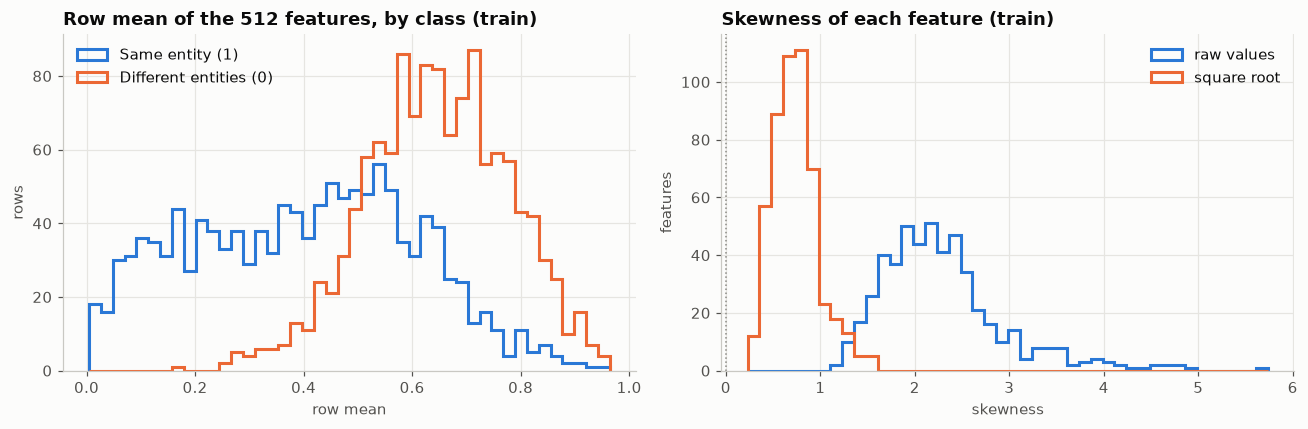

ROC-AUC of the negative row mean alone (train): 0.8362
median feature skewness: raw 2.18, square root 0.71


In [5]:
from scipy.stats import skew

row_mean = X_train.mean(axis=1)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(row_mean.min(), np.quantile(row_mean, 0.995), 45)
left.hist(row_mean[y_train == 1], bins=bins, histtype="step", color=BLUE, linewidth=2, label="Same entity (1)")
left.hist(row_mean[y_train == 0], bins=bins, histtype="step", color=ORANGE, linewidth=2, label="Different entities (0)")
left.set(title="Row mean of the 512 features, by class (train)", xlabel="row mean", ylabel="rows")
left.legend()

skew_raw, skew_sqrt = skew(X_train, axis=0), skew(np.sqrt(X_train), axis=0)
bins = np.linspace(min(skew_raw.min(), skew_sqrt.min()), skew_raw.max(), 45)
right.hist(skew_raw, bins=bins, histtype="step", color=BLUE, linewidth=2, label="raw values")
right.hist(skew_sqrt, bins=bins, histtype="step", color=ORANGE, linewidth=2, label="square root")
right.axvline(0, color=GRAY, linewidth=1, linestyle=":")
right.set(title="Skewness of each feature (train)", xlabel="skewness", ylabel="features")
right.legend()
fig.tight_layout()
plt.show()
print(f"ROC-AUC of the negative row mean alone (train): {roc_auc_score(y_train, -row_mean):.4f}")
print(f"median feature skewness: raw {np.median(skew_raw):.2f}, square root {np.median(skew_sqrt):.2f}")

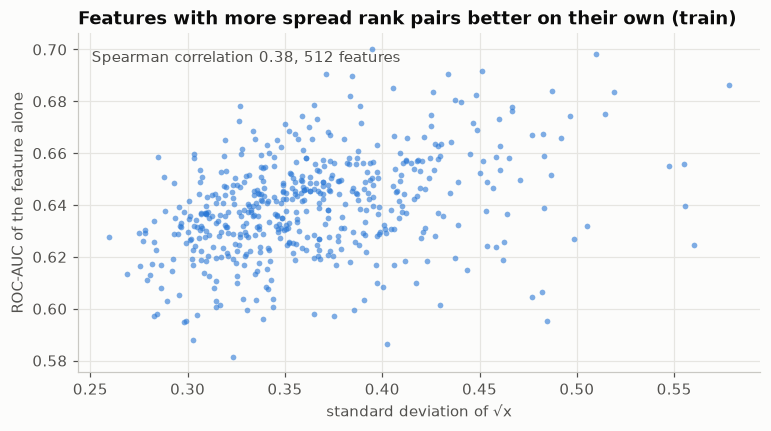

In [6]:
from scipy.stats import spearmanr

sqrt_train = np.sqrt(X_train)
spread = sqrt_train.std(axis=0)
feature_auc = np.array([roc_auc_score(y_train, -sqrt_train[:, j]) for j in range(sqrt_train.shape[1])])
rho = spearmanr(spread, feature_auc)[0]

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(spread, feature_auc, s=14, color=BLUE, alpha=0.6, linewidths=0)
ax.text(0.02, 0.95, f"Spearman correlation {rho:.2f}, 512 features", transform=ax.transAxes,
        color=INK_2, va="top")
ax.set(title="Features with more spread rank pairs better on their own (train)",
       xlabel="standard deviation of √x", ylabel="ROC-AUC of the feature alone")
plt.show()

## 3. Individual checkpoint baselines

All three baselines use the 512 raw features with no preprocessing, since tree splits do not depend on scaling.
Their settings were fixed before looking at validation: shallow trees (depth 3) with at least 30 training rows
per leaf. Validation ROC-AUC uses predicted probabilities. Accuracy uses a 0.5 threshold.

In [7]:
def evaluate(name, features, model, fit_seconds, p_train, p_valid, seed=SEED):
    return {"model": name, "feature set": features,
            "train ROC-AUC": roc_auc_score(y_train, p_train),
            "validation ROC-AUC": roc_auc_score(y_valid, p_valid),
            "validation accuracy": accuracy_score(y_valid, p_valid >= 0.5),
            "fit seconds": fit_seconds, "seed": seed}

results, valid_scores = [], {}

def fit_baseline(name, model):
    started = time.perf_counter()
    model.fit(X_train, y_train)
    seconds = time.perf_counter() - started
    p_train, p_valid = model.predict_proba(X_train)[:, 1], model.predict_proba(X_valid)[:, 1]
    valid_scores[name] = p_valid
    results.append(evaluate(name, "raw 512", model, seconds, p_train, p_valid))
    return model

### 3.1 Decision tree

depth 3, 8 leaves, leaf sizes 87-640 rows


,feature set,train ROC-AUC,validation ROC-AUC,validation accuracy,fit seconds,seed
model,,,,,,
Decision tree (depth 3),raw 512,0.7904,0.7473,0.6964,0.2755,42


validation confusion matrix [[TN, FP], [FN, TP]]: [[197, 83], [87, 193]]


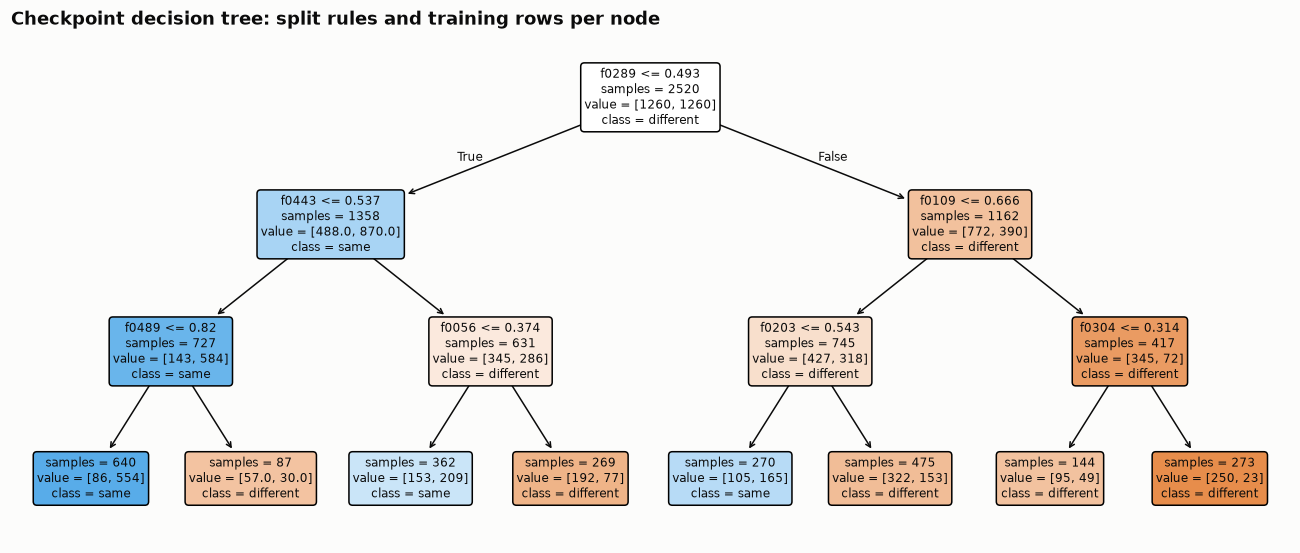

In [8]:
tree = fit_baseline("Decision tree (depth 3)",
                    DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=SEED))
leaf_sizes = tree.tree_.n_node_samples[tree.tree_.children_left == -1]
print(f"depth {tree.get_depth()}, {tree.get_n_leaves()} leaves, leaf sizes {leaf_sizes.min()}-{leaf_sizes.max()} rows")
display(pd.DataFrame([results[-1]]).set_index("model").round(4))
print("validation confusion matrix [[TN, FP], [FN, TP]]:",
      confusion_matrix(y_valid, valid_scores["Decision tree (depth 3)"] >= 0.5).tolist())

fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(tree, feature_names=FEATURES, class_names=["different", "same"], filled=True,
          impurity=False, rounded=True, fontsize=8, ax=ax)
ax.set_title("Checkpoint decision tree: split rules and training rows per node")
plt.show()

The tree gives only 8 distinct probabilities, so many validation pairs share a score. That limits its ROC-AUC.
The sweep below shows what depth does. Validation ROC-AUC peaks at depth 6, near 0.79, and stays flat after that.
Training ROC-AUC keeps rising until the 30-row leaf limit stops the tree growing at depth 8. The widening gap
means extra depth mostly memorises training pairs, and even the best single tree stays far below the ensembles.

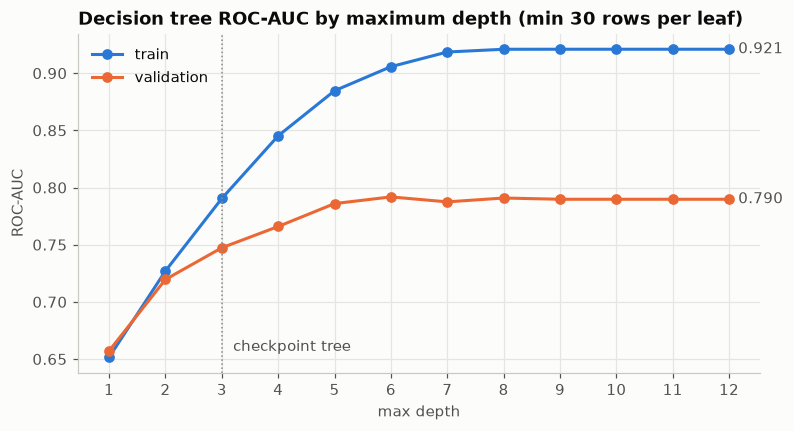

In [9]:
depths = range(1, 13)
sweep = []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=30, random_state=SEED).fit(X_train, y_train)
    sweep.append((roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
                  roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])))
sweep = np.array(sweep)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, sweep[:, 0], color=BLUE, marker="o", markersize=6, label="train")
ax.plot(depths, sweep[:, 1], color=ORANGE, marker="o", markersize=6, label="validation")
ax.axvline(3, color=GRAY, linewidth=1, linestyle=":")
ax.annotate("checkpoint tree", (3, sweep[:, 1].min()), xytext=(3.2, sweep[:, 1].min()), color=INK_2)
for series, color in ((sweep[:, 0], BLUE), (sweep[:, 1], ORANGE)):
    ax.annotate(f"{series[-1]:.3f}", (depths[-1], series[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK_2)
ax.set(title="Decision tree ROC-AUC by maximum depth (min 30 rows per leaf)", xlabel="max depth",
       ylabel="ROC-AUC", xticks=list(depths))
ax.legend(loc="upper left")
plt.show()

### 3.2 Random forest and gradient boosting

In [10]:
forest = fit_baseline("Random forest (200 trees, depth 3)", RandomForestClassifier(
    n_estimators=200, max_depth=3, min_samples_leaf=30, max_features="sqrt", bootstrap=True,
    random_state=SEED, n_jobs=-1))
booster = fit_baseline("XGBoost (100 trees, depth 3)", XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.05, min_child_weight=1, subsample=1.0,
    colsample_bytree=1.0, reg_lambda=1.0, reg_alpha=0.0, objective="binary:logistic", eval_metric="auc",
    tree_method="hist", device="cpu", random_state=SEED, n_jobs=4))
display(pd.DataFrame(results).set_index("model").round(4))

,feature set,train ROC-AUC,validation ROC-AUC,validation accuracy,fit seconds,seed
model,,,,,,
Decision tree (depth 3),raw 512,0.7904,0.7473,0.6964,0.2755,42
"Random forest (200 trees, depth 3)",raw 512,0.9388,0.8829,0.7893,0.3226,42
"XGBoost (100 trees, depth 3)",raw 512,0.9838,0.8955,0.8214,0.8319,42


Combining trees helps a lot. Two hundred depth-3 trees on random feature subsets reach far higher validation
ROC-AUC than one tree. Boosting, where each tree corrects the previous ones, adds a little more. All three still
fit the training rows much better than validation.

Extensive tuning of tree ensembles was done in separate experiments (see section 5). The best single tree model
reached about 0.93 validation ROC-AUC. A kernel SVM on square-root features beat every tree model, which is why
the final pipeline below is SVM-based.

## 4. Final pipeline

Four members, each fitted on `train.csv` only, then combined by rank pooling with fixed weights:

| Member | Input | Model | Weight |
|---|---|---|---|
| Full SVM | √x, centred, multiplied by √(feature spread), all 512 features | RBF SVM, C = 10, γ = 1.25 × scale | 0.3115 |
| PCA SVM | the same input, first 255 principal components | RBF SVM, C = 10, γ = 1.5 × scale | 0.3115 |
| LightGBM | raw 512 + 6 row summaries + 64 principal components + 6 distance summaries + 27 neighbour features (section 4.1) | 800 trees, 31 leaves | 0.300 |
| Polynomial SVM | √x, standardized | degree-2 kernel, C = 100 | 0.0769 |

* **Spread weighting** for the two RBF SVMs is explained in section 2. The polynomial SVM keeps standardized
  inputs, as it was tuned that way.
* **γ × scale** means a multiple of scikit-learn's `gamma="scale"` heuristic, 1 / (n_features × variance),
  computed on the fitting rows.
* **Calibration.** Each SVM is wrapped in sigmoid (Platt) calibration with 3 shuffled inner folds of the
  training rows, so every member outputs a probability.
* **Rank pooling.** Each member's probability is replaced by its position among that member's out-of-fold
  probabilities on the training rows, a number between 0 and 1 found by linear interpolation. The final score
  is the weighted sum of the four positions. Positions cap how far any one member can pull a row, so a single
  overconfident member cannot override the others. The positions come from training rows only and use no
  labels, so a test row's score never depends on other test rows. The scores are rank positions, not
  calibrated probabilities; ROC-AUC uses only their order.
* **Out-of-fold reference.** Each member is refitted on four fifths of the training rows and predicts the
  remaining fifth, over 5 folds (the first repeat of the 5×2 split used in the search). These 2520
  out-of-fold probabilities per member are the reference for the positions.
* **How the weights were chosen.** The two SVMs and LightGBM were first weighted 0.45 / 0.45 / 0.10. The
  polynomial SVM was then added at 0.10 and the other weights scaled by 0.9, giving 0.405 / 0.405 / 0.09 / 0.10.
  Once LightGBM had the neighbour features, its weight was chosen from 0.09, 0.15, 0.20 and 0.30. The other
  three kept their proportions, 0.405 : 0.405 : 0.10, scaled to fill the remaining 0.70. All settings were
  chosen by repeated 5×2 stratified cross-validation on the training set. Validation checked each frozen
  finalist once.
* **Why each member.** The two SVMs see the data through different geometries, all 512 dimensions versus the
  main principal directions, so their errors differ. The polynomial kernel adds pairwise feature interactions.
  LightGBM adds tree-based thresholds on the raw values, row summaries and neighbour features.

In [11]:
class ScaledGammaSVC(ClassifierMixin, BaseEstimator):  # mixin first, so every sklearn version sees a classifier
    # RBF SVM with gamma = multiplier / (n_features * X.var()), computed on the fitting rows only.
    def __init__(self, multiplier=1.0, C=10.0, tol=1e-4, cache_size=512, random_state=SEED):
        self.multiplier, self.C = multiplier, C
        self.tol, self.cache_size, self.random_state = tol, cache_size, random_state

    def fit(self, X, y):
        X = np.ascontiguousarray(X, dtype=np.float64)
        self.gamma_ = float(self.multiplier) / (X.shape[1] * float(X.var()))
        self.estimator_ = SVC(kernel=partial(rbf_kernel, gamma=self.gamma_), C=self.C, tol=self.tol,
                              cache_size=self.cache_size, random_state=self.random_state)
        with threadpool_limits(limits=1):
            self.estimator_.fit(X, y)
        self.classes_ = self.estimator_.classes_
        return self

    def decision_function(self, X):
        with threadpool_limits(limits=1):
            return self.estimator_.decision_function(np.ascontiguousarray(X, dtype=np.float64))

    def predict(self, X):
        return self.estimator_.predict(np.ascontiguousarray(X, dtype=np.float64))


class PolynomialSVC(ClassifierMixin, BaseEstimator):
    # Degree-2 polynomial-kernel SVM with gamma = 1 / (n_features * X.var()) from the fitting rows.
    def __init__(self, C=1.0, coef0=1.0):
        self.C, self.coef0 = C, coef0

    def fit(self, X, y):
        X = np.ascontiguousarray(X, dtype=np.float64)
        self.gamma_ = 1.0 / (X.shape[1] * float(X.var()))
        self.estimator_ = SVC(kernel=partial(polynomial_kernel, degree=2, gamma=self.gamma_, coef0=self.coef0),
                              C=self.C, tol=1e-4, cache_size=512, random_state=SEED)
        with threadpool_limits(limits=1):
            self.estimator_.fit(X, y)
        assert self.estimator_.fit_status_ == 0, "polynomial SVM did not converge"
        self.classes_ = self.estimator_.classes_
        return self

    def decision_function(self, X):
        with threadpool_limits(limits=1):
            return self.estimator_.decision_function(np.ascontiguousarray(X, dtype=np.float64))

    def predict(self, X):
        return self.estimator_.predict(np.ascontiguousarray(X, dtype=np.float64))


def calibrated(pipeline):
    # Platt scaling on 3 shuffled inner folds of the fitting rows; the full pipeline is refitted on all of them.
    return CalibratedClassifierCV(pipeline, method="sigmoid", ensemble=False, n_jobs=1,
                                  cv=StratifiedKFold(3, shuffle=True, random_state=SEED))


class SpreadScaler(TransformerMixin, BaseEstimator):
    # sqrt(x), minus the training mean, divided by the training standard deviation raised to `alpha`.
    # alpha = 1 standardizes, alpha = 0 keeps the natural spread, alpha = -0.5 multiplies by sqrt(spread).
    def __init__(self, alpha=-0.5):
        self.alpha = alpha

    def fit(self, X, y=None):
        z = np.sqrt(np.ascontiguousarray(X, dtype=np.float64))
        self.mean_, std = z.mean(axis=0), z.std(axis=0)
        self.scale_ = np.where(std > 0, std, 1.0) ** self.alpha
        return self

    def transform(self, X):
        return (np.sqrt(np.ascontiguousarray(X, dtype=np.float64)) - self.mean_) / self.scale_


def svm_member(multiplier, pca_components=None):
    steps = [("spread", SpreadScaler(alpha=-0.5))]
    if pca_components:
        steps.append(("pca", PCA(n_components=pca_components, svd_solver="full", whiten=False,
                                 random_state=SEED)))
    steps.append(("model", ScaledGammaSVC(multiplier=multiplier, C=10.0)))
    return calibrated(Pipeline(steps))


def polynomial_member():
    return calibrated(Pipeline([("sqrt", FunctionTransformer(np.sqrt, validate=True)),
                                ("scaler", StandardScaler()),
                                ("model", PolynomialSVC(C=100.0, coef0=0.0))]))

### 4.1 LightGBM with neighbour features

LightGBM sees the raw values, 6 row summaries and 64 principal components, as before, plus 33 new inputs:

* **6 distance summaries** of each row: its raw L1 and L2 norms and their ratio, its mean absolute deviation
  from the row median, and its mean absolute value and root mean square in the spread-weighted √x space of
  the RBF SVMs.
* **27 neighbour features**, from L1 (city-block) distances in that same space to a bank of training rows:
  * for the 5, 15 and 45 nearest bank rows: the share that are matching pairs, the same share weighted by
    inverse distance, and the mean distance;
  * the mean distance to the 15 nearest bank rows of each class, and the normalized contrast of the two;
  * the same 12 summaries after **local scaling**: each distance is divided by √(r<sub>row</sub> × r<sub>bank row</sub>),
    where r is the distance to the 15th nearest bank row (a bank row's own radius leaves the row itself out).
    This puts dense and sparse regions of the space on a common scale;
  * three radius ratios: r<sub>5</sub> / r<sub>15</sub>, r<sub>15</sub> / r<sub>45</sub>, and r<sub>15</sub>
    relative to the bank's median radius.
* **No row ever sees its own label.** The fitting rows are split into 3 folds without looking at the labels.
  Each fitting row's neighbour features come from the bank of the other two folds, so its own label is never
  among its neighbours. Any other row, from validation or test, averages its features over the three banks.
  Each bank fits its spread scaling on its own rows. A validation or test row's features therefore depend
  only on the training rows and on the row itself, never on other rows of its file.
* **Why it helps.** The neighbour features give LightGBM a direct summary of how similar training pairs were
  labelled, which the SVMs use only implicitly through their kernels. On its own, LightGBM's ten-fold
  cross-validated ROC-AUC rose from 0.918 to 0.933, level with the SVMs, which is why its weight could rise
  to 0.30.


In [12]:
def row_summaries(values):
    # Six statistics of each row's own 512 values; nothing is fitted.
    mean, std = values.mean(axis=1), values.std(axis=1)
    cv = np.divide(std, mean, out=np.zeros_like(std), where=mean > 0)
    return np.column_stack([mean, np.median(values, axis=1), np.log1p(values).mean(axis=1),
                            std, values.max(axis=1), cv])


def distance_summaries(values, spread):
    # Six norms of each row: raw L1 and L2, their ratio, mean absolute deviation from the row median,
    # and the mean absolute value and root mean square of the row in the spread-weighted sqrt space.
    l1, l2 = np.abs(values).sum(axis=1), np.linalg.norm(values, axis=1)
    return np.column_stack([l1, l2, l1 / (np.sqrt(values.shape[1]) * np.maximum(l2, 1e-12)),
                            np.mean(np.abs(values - np.median(values, axis=1, keepdims=True)), axis=1),
                            np.mean(np.abs(spread), axis=1), np.sqrt(np.mean(spread ** 2, axis=1))])


def neighbour_stats(distances, labels):
    # 12 summaries of each row's distances to the bank rows: for its 5, 15 and 45 nearest bank rows the share of
    # matching pairs, the inverse-distance-weighted share and the mean distance; then the mean distance to the
    # 15 nearest bank rows of each class and their normalized contrast.
    order = np.argsort(distances, axis=1, kind="stable")[:, :45]
    near, near_labels = np.take_along_axis(distances, order, axis=1), labels[order]
    columns = []
    for k in (5, 15, 45):
        w = 1 / np.maximum(near[:, :k], 1e-8)
        columns += [near_labels[:, :k].mean(1), (w * near_labels[:, :k]).sum(1) / w.sum(1), near[:, :k].mean(1)]
    class_distance = [np.sort(distances[:, labels == c], axis=1)[:, :15].mean(1) for c in (0, 1)]
    columns += [*class_distance,
                (class_distance[0] - class_distance[1]) / (class_distance[0] + class_distance[1] + 1e-12)]
    return np.column_stack(columns)


class NeighbourBank:
    # A bank of training rows: L1 (city-block) distances in the spread-weighted sqrt space, scaled on the bank.
    def __init__(self, values, labels):
        self.scaler = SpreadScaler(alpha=-0.5).fit(values)
        self.reference, self.labels = self.scaler.transform(values), labels
        distances = cdist(self.reference, self.reference, metric="cityblock")
        np.fill_diagonal(distances, np.inf)  # a bank row's radius excludes the row itself
        self.radii = np.maximum(np.partition(distances, 14, axis=1)[:, 14], 1e-12)

    def features(self, values):
        # 27 features: 12 summaries of the raw distances, 12 of the locally scaled distances, 3 radius ratios.
        l1 = cdist(self.scaler.transform(values), self.reference, metric="cityblock")
        ordered = np.sort(l1, axis=1)
        r5, r15, r45 = (np.maximum(ordered[:, k - 1], 1e-12) for k in (5, 15, 45))
        local = l1 / np.sqrt(r15[:, None] * self.radii[None, :])
        ratios = np.column_stack([r5 / r15, r15 / r45, r15 / np.median(self.radii)])
        return np.column_stack([neighbour_stats(l1, self.labels), neighbour_stats(local, self.labels), ratios])


class LightGBMMember:
    # Raw 512 + 6 row summaries + 64 principal components of the standardized raw features
    # + 6 distance summaries + 27 neighbour features = 615 inputs, all fitted on the fitting rows.
    params = dict(n_estimators=800, learning_rate=0.03, num_leaves=31, min_child_samples=30,
                  reg_lambda=10.0, reg_alpha=0.1, colsample_bytree=0.7, subsample=0.8, subsample_freq=1,
                  max_bin=127, objective="binary", verbosity=-1, deterministic=True, force_col_wise=True)

    def base_design(self, values):
        with threadpool_limits(limits=1, user_api="blas"):
            components = self.pca_.transform(self.scaler_.transform(values))
        return np.hstack([values, row_summaries(values), components,
                          distance_summaries(values, self.spread_.transform(values))])

    def fit(self, X, y):
        self.scaler_ = StandardScaler().fit(X)
        with threadpool_limits(limits=1, user_api="blas"):
            self.pca_ = PCA(n_components=64, svd_solver="full", whiten=False).fit(self.scaler_.transform(X))
        self.spread_ = SpreadScaler(alpha=-0.5).fit(X)
        # Three folds split without labels; each fitting row is described by the bank of the other two folds,
        # so its own label is never among its neighbours.
        self.banks_, neighbours = [], np.full((len(y), 27), np.nan)
        for bank, query in KFold(3, shuffle=True, random_state=43).split(X):
            self.banks_.append(NeighbourBank(X[bank], y[bank]))
            neighbours[query] = self.banks_[-1].features(X[query])
        self.model_ = LGBMClassifier(**self.params, random_state=SEED, n_jobs=1)
        with threadpool_limits(limits=1), warnings.catch_warnings():
            warnings.simplefilter("ignore", UserWarning)
            self.model_.fit(np.hstack([self.base_design(X), neighbours]), y)
        return self

    def predict_proba(self, X):
        # Any other row averages its neighbour features over the three banks; rows never affect each other.
        neighbours = np.zeros((len(X), 27))
        for bank in self.banks_:
            neighbours += bank.features(X) / 3
        with threadpool_limits(limits=1):
            return self.model_.predict_proba(np.hstack([self.base_design(X), neighbours]))


### 4.2 Members, weights and rank pooling

In [13]:
# Each member is created by a factory, so every fit starts from a fresh, unfitted model.
MEMBERS = {
    "Full SVM (sqrt, RBF)": (lambda: svm_member(multiplier=1.25), "sqrt 512, centred x sqrt(spread)"),
    "PCA SVM (sqrt, PCA 255, RBF)": (lambda: svm_member(multiplier=1.5, pca_components=255),
                                     "sqrt 512, centred x sqrt(spread) -> PCA 255"),
    "LightGBM": (LightGBMMember, "raw + summaries + PCA 64 + distances + kNN (615)"),
    "Polynomial SVM (degree 2)": (polynomial_member, "sqrt 512, standardized"),
}
for name, (factory, _) in MEMBERS.items():
    model = factory()
    if isinstance(model, CalibratedClassifierCV):
        assert is_classifier(model.estimator), f"{name}: pipeline is not recognised as a classifier"

# Fixed pooling weights (see the table above): LightGBM 0.30; the other three keep their earlier proportions
# 0.405 : 0.405 : 0.10, scaled to fill the remaining 0.70.
LIGHTGBM_WEIGHT = 0.30
WEIGHTS = np.array([0.405, 0.405, 0.09, 0.10]) * ((1 - LIGHTGBM_WEIGHT) / 0.91)
WEIGHTS[2] = LIGHTGBM_WEIGHT
assert np.isclose(WEIGHTS.sum(), 1.0, rtol=0, atol=1e-12)
print("pooling weights:", WEIGHTS.round(4).tolist())


# Rank pooling: positions among the training out-of-fold probabilities of each member.
FOLDS = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED).split(X_train, y_train))[:5]


def rank_position(reference_column, values):
    # Position of each value among one member's training out-of-fold probabilities, linearly interpolated.
    ordered = np.sort(reference_column)
    levels = (np.arange(len(ordered)) + 0.5) / len(ordered)
    return np.interp(values, ordered, levels)


def rank_pool(probabilities, reference, weights=WEIGHTS):
    positions = np.column_stack([rank_position(reference[:, m], probabilities[:, m])
                                 for m in range(probabilities.shape[1])])
    return positions @ weights


pooling weights: [0.3115, 0.3115, 0.3, 0.0769]


### 4.3 Out-of-fold reference, final fit and predictions

In [14]:
def fit_member(factory, X, y):
    model = factory()
    model.fit(X, y)
    return model


# Step 1: out-of-fold member probabilities on the training rows, the reference for rank pooling.
oof_start = time.perf_counter()
oof_reference = np.full((len(y_train), len(MEMBERS)), np.nan)
with threadpool_limits(limits=1):
    for fold, (fit_idx, eval_idx) in enumerate(FOLDS):
        for m, (factory, _) in enumerate(MEMBERS.values()):
            fold_model = fit_member(factory, X_train[fit_idx], y_train[fit_idx])
            oof_reference[eval_idx, m] = fold_model.predict_proba(X_train[eval_idx])[:, 1]
        print(f"out-of-fold reference: fold {fold + 1}/5 done")
assert np.isfinite(oof_reference).all()
oof_seconds = time.perf_counter() - oof_start

# Step 2: final members on all training rows.
fit_seconds, fitted = {}, {}
fit_start = time.perf_counter()
with threadpool_limits(limits=1):
    for name, (factory, _) in MEMBERS.items():
        started = time.perf_counter()
        fitted[name] = fit_member(factory, X_train, y_train)
        fit_seconds[name] = time.perf_counter() - started
        print(f"fitted {name:30s} {fit_seconds[name]:6.1f} s")
total_fit_seconds = oof_seconds + time.perf_counter() - fit_start

# Step 3: predictions. Validation for evaluation; test timed on its own, including rank pooling.
member_valid, member_test = {}, {}
with threadpool_limits(limits=1):
    for name, model in fitted.items():
        member_valid[name] = model.predict_proba(X_valid)[:, 1]
    test_start = time.perf_counter()
    for name, model in fitted.items():
        member_test[name] = model.predict_proba(X_test)[:, 1]
    final_test = rank_pool(np.column_stack([member_test[n] for n in MEMBERS]), oof_reference)
    test_prediction_seconds = time.perf_counter() - test_start
valid_matrix = np.column_stack([member_valid[n] for n in MEMBERS])
final_valid = rank_pool(valid_matrix, oof_reference)

print(f"\nout-of-fold reference {oof_seconds:.1f} s; total fit time {total_fit_seconds:.1f} s")
print(f"test prediction {test_prediction_seconds:.2f} s for {len(X_test)} rows "
      f"({1000 * test_prediction_seconds / len(X_test):.2f} ms per row)")
assert test_prediction_seconds < 120, "test predictions must take under 2 minutes after fitting"

out-of-fold reference: fold 1/5 done
out-of-fold reference: fold 2/5 done
out-of-fold reference: fold 3/5 done
out-of-fold reference: fold 4/5 done
out-of-fold reference: fold 5/5 done
fitted Full SVM (sqrt, RBF)              0.8 s
fitted PCA SVM (sqrt, PCA 255, RBF)      1.2 s
fitted LightGBM                         12.0 s
fitted Polynomial SVM (degree 2)         0.6 s

out-of-fold reference 58.3 s; total fit time 72.9 s
test prediction 2.29 s for 1116 rows (2.05 ms per row)


In [15]:
for name, (_, features) in MEMBERS.items():
    valid_scores[name] = member_valid[name]
    results.append({"model": name, "feature set": features, "train ROC-AUC": np.nan,
                    "validation ROC-AUC": roc_auc_score(y_valid, member_valid[name]),
                    "validation accuracy": accuracy_score(y_valid, member_valid[name] >= 0.5),
                    "fit seconds": fit_seconds[name], "seed": SEED})
FINAL = "Final ensemble (rank pooling)"
valid_scores[FINAL] = final_valid
results.append({"model": FINAL, "feature set": "the four members, fixed weights", "train ROC-AUC": np.nan,
                "validation ROC-AUC": roc_auc_score(y_valid, final_valid),
                "validation accuracy": accuracy_score(y_valid, final_valid >= 0.5),
                "fit seconds": total_fit_seconds, "seed": SEED})
print(f"final validation ROC-AUC: {roc_auc_score(y_valid, final_valid):.6f}")
print("final validation confusion matrix at 0.5 [[TN, FP], [FN, TP]]:",
      confusion_matrix(y_valid, final_valid >= 0.5).tolist())


final validation ROC-AUC: 0.958112
final validation confusion matrix at 0.5 [[TN, FP], [FN, TP]]: [[245, 35], [31, 249]]


## 5. Comparison and experiment table

In [16]:
table = pd.DataFrame(results).set_index("model")
shown = table.round({"train ROC-AUC": 4, "validation ROC-AUC": 4, "validation accuracy": 4, "fit seconds": 1})
display(shown.astype(object).where(shown.notna(), "–"))

,feature set,train ROC-AUC,validation ROC-AUC,validation accuracy,fit seconds,seed
model,,,,,,
Decision tree (depth 3),raw 512,0.7904,0.7473,0.6964,0.3,42
"Random forest (200 trees, depth 3)",raw 512,0.9388,0.8829,0.7893,0.3,42
"XGBoost (100 trees, depth 3)",raw 512,0.9838,0.8955,0.8214,0.8,42
"Full SVM (sqrt, RBF)","sqrt 512, centred x sqrt(spread)",–,0.9516,0.8679,0.8,42
"PCA SVM (sqrt, PCA 255, RBF)","sqrt 512, centred x sqrt(spread) -> PCA 255",–,0.9518,0.8732,1.2,42
LightGBM,raw + summaries + PCA 64 + distances + kNN (615),–,0.9528,0.8839,12.0,42
Polynomial SVM (degree 2),"sqrt 512, standardized",–,0.9158,0.8286,0.6,42
Final ensemble (rank pooling),"the four members, fixed weights",–,0.9581,0.8821,72.9,42


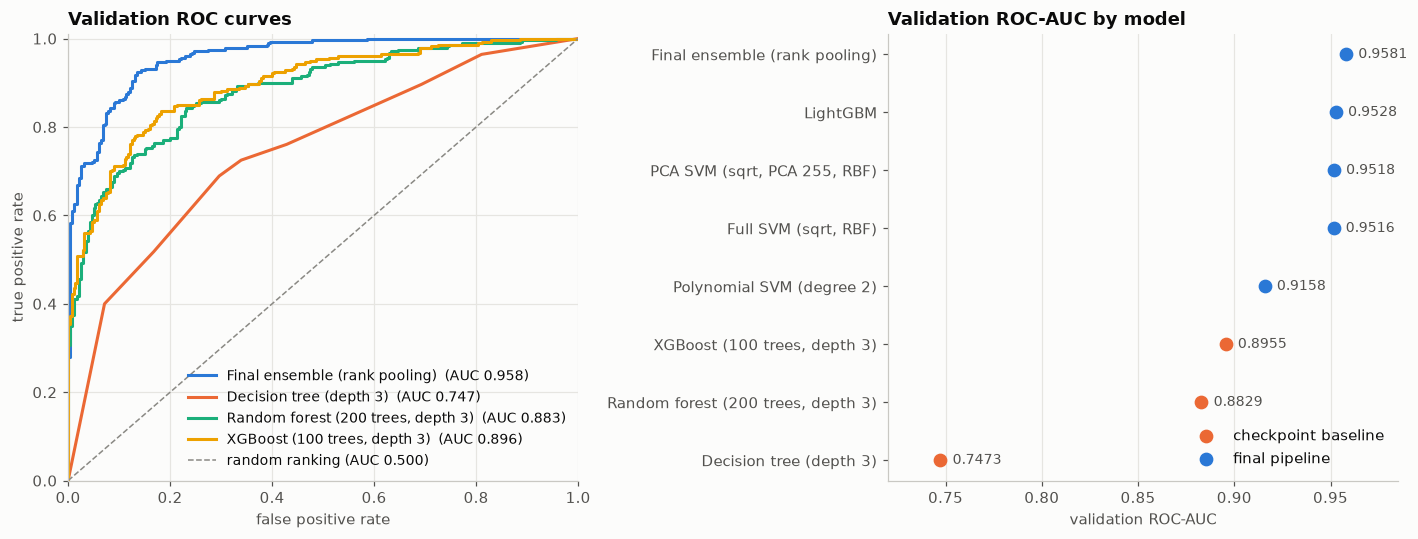

In [17]:
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))

curves = [(FINAL, BLUE), ("Decision tree (depth 3)", ORANGE),
          ("Random forest (200 trees, depth 3)", AQUA), ("XGBoost (100 trees, depth 3)", YELLOW)]
for name, color in curves:
    fpr, tpr, _ = roc_curve(y_valid, valid_scores[name])
    left.plot(fpr, tpr, color=color, label=f"{name}  (AUC {roc_auc_score(y_valid, valid_scores[name]):.3f})")
left.plot([0, 1], [0, 1], color=GRAY, linewidth=1, linestyle="--", label="random ranking (AUC 0.500)")
left.set(title="Validation ROC curves", xlabel="false positive rate", ylabel="true positive rate",
         xlim=(0, 1), ylim=(0, 1.01))
left.legend(loc="lower right", fontsize=9)

ordered = table["validation ROC-AUC"].sort_values()
is_baseline = ordered.index.isin(["Decision tree (depth 3)", "Random forest (200 trees, depth 3)",
                                   "XGBoost (100 trees, depth 3)"])
positions = np.arange(len(ordered))
right.scatter(ordered[is_baseline], positions[is_baseline], s=64, color=ORANGE, zorder=3,
              label="checkpoint baseline")
right.scatter(ordered[~is_baseline], positions[~is_baseline], s=64, color=BLUE, zorder=3,
              label="final pipeline")
for y_pos, value in zip(positions, ordered):
    right.annotate(f"{value:.4f}", (value, y_pos), xytext=(8, 0), textcoords="offset points",
                   va="center", color=INK_2, fontsize=9)
right.set_yticks(positions, ordered.index)
right.set(title="Validation ROC-AUC by model", xlabel="validation ROC-AUC", xlim=(0.72, 0.985))
right.grid(axis="y", visible=False)
right.legend(loc="lower right")
fig.tight_layout()
plt.show()

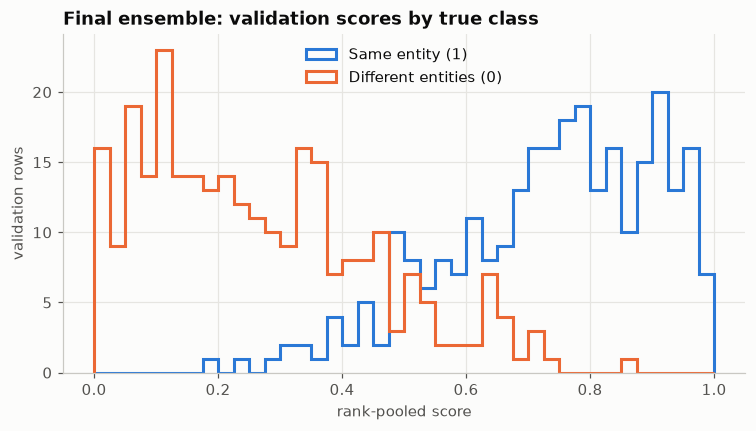

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 41)
ax.hist(final_valid[y_valid == 1], bins=bins, histtype="step", color=BLUE, linewidth=2, label="Same entity (1)")
ax.hist(final_valid[y_valid == 0], bins=bins, histtype="step", color=ORANGE, linewidth=2,
        label="Different entities (0)")
ax.set(title="Final ensemble: validation scores by true class", xlabel="rank-pooled score",
       ylabel="validation rows")
ax.legend(loc="upper center")
plt.show()

### How the final model was chosen

The models above are the ones this notebook refits. The final configuration came out of a longer series of
experiments. Every setting was chosen by repeated 5×2 stratified cross-validation on `train.csv`, which was the
primary selection metric. One frozen finalist per experiment was then checked once on `validation.csv`. Key steps,
with the ten-fold cross-validation ROC-AUC and the validation ROC-AUC:

| Step | Model | Features | 10-fold CV ROC-AUC | Validation ROC-AUC |
|---|---|---|---|---|
| 1 | Decision tree, depth 3 | raw 512 | 0.7254 | 0.7473 |
| 2 | Random forest, 200 × depth 3 | raw 512 | 0.8779 | 0.8829 |
| 3 | XGBoost, 100 × depth 3 | raw 512 | 0.8922 | 0.8955 |
| 4 | Tuned ExtraTrees + XGBoost average | raw 512 + 6 row summaries | 0.9148 | 0.9253 |
| 5 | Best single tree model, CatBoost | raw + summaries + PCA 64 | 0.9200 | 0.9315 |
| 6 | Calibrated RBF SVM on log1p + XGBoost | log1p for the SVM, as step 5 for XGBoost | 0.9288 | 0.9429 |
| 7 | RBF SVM on √x + XGBoost + LightGBM | √x for the SVM | 0.9310 | 0.9477 |
| 8 | Two RBF SVMs (full + PCA 255) + LightGBM | √x, PCA 255 branch | 0.9322 | 0.9500 |
| 9 | Step 8 + degree-2 polynomial SVM | as above | 0.9323 | 0.9526 |
| 10 | Step 9 with centred, not standardized, RBF SVM inputs | √x centred for the two RBF SVMs | 0.9338 | 0.9544 |
| 11 | Step 10 with features multiplied by √(spread) in the RBF SVMs | √x, centred, × √(spread) | 0.9342 | 0.9548 |
| 12 | Step 11 with rank pooling instead of log-odds pooling | same members and weights | 0.9344 | 0.9559 |
| 13 | Step 12 + L1 neighbour features for LightGBM (weight 0.09) | + 6 distance summaries + 12 neighbour features | 0.9350 | 0.9562 |
| 14 | **Step 13 + locally scaled neighbour features, LightGBM weight 0.30 (final)** | + 12 locally scaled summaries + 3 radius ratios | **0.9373** | **0.9581** |

Cross-validation scores sit below validation because each fold's models are trained on 80% of the training rows.
They are comparable with each other, not with the validation column. Every adopted step raised both. Steps 13
and 14 were scored with a stricter, nested cross-validation: each outer fold's rank reference came from five inner
folds of that fold's own fitting rows. Under it, step 12 also scores 0.9344.

Two provenance notes. Step 10 kept only the SVM part of a frozen finalist that also jittered LightGBM; that
split was decided after seeing both parts on validation. Step 11 chose its spread exponent from five
predeclared settings, and the chosen value sat at the edge of the tested range. Step 14 chose LightGBM's weight
from 0.09, 0.15, 0.20 and 0.30, and the best also sat at the top of that grid.

Before rank pooling, another step was tried and not kept: a stacked logistic combiner that also saw each row's magnitude
(feature-weighted stacking). It won a nested cross-validation by 0.0005 and raised validation ROC-AUC to
0.9556, but both gains were within noise and the public score fell. The simpler fixed blend was kept.

**Why this model.** It has the best validation (0.9581) and public (0.94591) scores of every configuration.
Every change from step 6 onward improved both cross-validation and validation, and every one uploaded also raised
the public score. Step 14 was frozen by nested cross-validation, where it beat step 12 on all 10 folds, before
validation was read. Its validation gain over step 12, +0.0022, has a bootstrap interval entirely above zero.
The pipeline trains in about 72 seconds on one CPU core and has no stochastic step left unseeded.

**Why not a tree model.** The features act like many weak, same-direction signals spread over 512 columns.
Tree ensembles combine those less efficiently than a kernel that measures distance over all columns at once.
Even with tuning, the best tree model stayed about 0.017 below a single √x SVM on validation.

**Limitations.** Validation has been consulted across many experiments, so its scores are slightly optimistic.
The public score runs about 0.01 below validation. Labels may contain some noise. Cross-validation folds are
split by row, not by the hidden entities, which the data does not identify. LightGBM's weight sat at the top of
its tested grid. The stability checks over seeds and weight perturbations were run on step 12, before the
neighbour features were added.

### Every step and experiment behind the final model

This notebook refits only the final model, with its settings fixed. The settings came from the experiments below,
run on the training data in this order.

**Common protocol, used by every experiment**

* **Data roles.** Models, scalers, principal components, calibration and pooling were always fitted on the
  training rows only. The validation rows only scored finished candidates. The test rows were used only to
  predict when a submission file was written.
* **Search on training data.** Repeated stratified 5-fold cross-validation, 2 repeats, seed 42, with the same ten
  folds in every experiment, so all comparisons are paired. Settings were screened on the first five folds and
  the best confirmed on all ten.
* **One finalist, one validation read.** Each experiment fixed its single finalist before looking at validation,
  then scored it once. The change in validation ROC-AUC was summarized with a paired, stratified bootstrap of
  2000 resamples.
* **Adoption rule.** A change was kept only if it improved both cross-validation and validation. Later
  experiments also required the cross-validation gain to exceed its fold-to-fold noise before validation was read.
* **Checks.** New code first had to reproduce the existing models exactly, and each experiment's results were
  recomputed independently.

**Experiments, in order**

| # | What was done | Outcome |
|---|---|---|
| 1 | **Training-data audit.** Class balance, missing values, duplicates, feature distributions and single-feature signal, on the training rows only. | Balanced, clean data. Every feature is lower for matching pairs, and the row mean alone reaches training ROC-AUC 0.836. |
| 2 | **Checkpoint baselines.** Decision tree (depth 3), random forest (200 trees of depth 3) and XGBoost (100 trees of depth 3), with settings fixed in advance. | Cross-validation ROC-AUC 0.7254, 0.8779 and 0.8922; validation 0.7473, 0.8829 and 0.8955. |
| 3 | **Tree-model tuning.** Grids over tree depth, leaf size and pruning, forest and ExtraTrees size and feature sampling, and XGBoost depth, column sampling and regularisation. Six row summaries, monotone constraints, seed averaging and forest + boosting averages. | Row summaries helped the single tree most. The tuned ExtraTrees + XGBoost average reached cross-validation 0.9148 and validation 0.9253 (public 0.91633). Boosting without feature interactions and extra row statistics did not help. |
| 4 | **Boosting search and representations.** CatBoost, a Bayesian search over XGBoost and CatBoost settings, and appending 16 or 64 principal components or a row-relative profile to the features. | 64 principal components helped: XGBoost + CatBoost reached cross-validation 0.9215 and validation 0.9318. The row profile did not. |
| 5 | **Label smoothing, booster pooling and a logistic member.** Boosters trained on softened labels, weighted and log-odds averages of boosters, and logistic regression added to the blend. | Better calibrated probabilities, but no reliable ROC-AUC gain on validation. |
| 6 | **Other model families.** Calibrated RBF SVM, linear discriminant analysis, explainable boosting, LightGBM, ExtraTrees and random forest, each tuned, then combined in 295 fixed ensembles. | The RBF SVM was the best single model (cross-validation 0.9269, validation 0.9474). An SVM + XGBoost blend scored 0.9288 / 0.9429 (public 0.93343), and shifting weight towards the SVM gave 0.9299 / 0.9471 (public 0.93702). |
| 7 | **SVM kernels and input compression.** Chi-squared and Laplacian kernels, and square-root, power, logarithm and rank-normal inputs with a bandwidth grid. | The square root was the best compression, with weaker and stronger ones both worse. The other kernels lost on validation. |
| 8 | **A second SVM on principal components.** An RBF SVM on 255 principal components next to the full SVM, plus LightGBM, an idea taken from a teammate's pipeline. Then refinements of PCA size, bandwidth, C and whitening. | Cross-validation 0.9322, validation 0.9500 (public 0.93905). The refinements gave nothing further. |
| 9 | **More members.** QDA, degree-2 and degree-3 polynomial SVMs, pairwise interaction features for LightGBM, removal of each PCA part, and an SVM with extra row summaries. | The degree-2 polynomial SVM at 10% weight helped: cross-validation 0.9323, validation 0.9526 (public 0.93971). Removing any PCA part hurt, and the rest did not help. |
| 10 | **Robustness and diversity.** Bagged SVMs, down-weighting training rows the model strongly contradicted (possible label noise), scale-free SVMs and nearest neighbours. | Bagging hurt, noise weights were neutral and the scale-free SVM added only a little. None was kept. |
| 11 | **Scaling and augmentation.** Centring instead of standardizing the SVM inputs, partial and robust scaling, and jittered copies and mixup for the SVM and LightGBM. | Centring was a clear gain: cross-validation 0.9338, validation 0.9544 (public 0.94360). Augmentation did nothing. |
| 12 | **Spread weighting.** Multiplying each centred feature by a power of its spread. Later, stronger powers, per-feature relevance weights, other PCA sizes and this geometry for the polynomial SVM. | Power 0.5 helped: cross-validation 0.9342, validation 0.9548 (public 0.94413). The later variants plateaued. |
| 13 | **Stacking.** Logistic-regression stacking built so that no fold saw its own labels, non-negative and ridge combiners over up to 25 models, and a combiner that also saw each row's magnitude. | Only the magnitude-aware combiner beat fixed weights. It raised cross-validation to 0.9346 and validation to 0.9556 but lowered the public score, so it was dropped. |
| 14 | **Neural networks and other boosters.** MLPs with three optimisers and L2 or elastic-net penalties, an encoder trained with an added supervised-contrastive loss, and deeper or different boosters in place of LightGBM. | The networks improved on their own, but none helped the ensemble on validation. Deeper trees did not help any booster. |
| 15 | **Rank pooling.** Each member's score replaced by its position among that member's out-of-fold scores on the training rows, then weighted as before. | Cross-validation 0.9344 (better on 8 of 10 folds), validation 0.9559 with a bootstrap interval above zero (public 0.94434). It was the final model until row 18. |
| 16 | **Final checks of the rank-pooled model.** Refits under four seeds, weights perturbed by ±30%, and timing of training and prediction. | Stable across seeds and weights. About a minute to train on one CPU core, and 0.3 ms per test row. |
| 17 | **Distance and neighbour features; a neural feature selector.** Six row norms, then summaries of each row's 5, 15 and 45 nearest training rows (share of matching pairs, distances) under L1 or L2 distance, built so no training row sees its own label, added to LightGBM. Separately, a small neural network used to select 256 features, or to embed the rows, in place of the PCA SVM's input. | L1 neighbour features helped: nested cross-validation 0.9350 (better on 9 of 10 folds), validation 0.9562. The norms alone and both neural variants did not help. |
| 18 | **Local scaling and LightGBM's weight.** L1 plus L2 neighbour summaries, or L1 plus locally scaled distances and radius ratios, each with LightGBM's weight at 0.09, 0.15, 0.20 or 0.30. | Local scaling at weight 0.30 won: nested cross-validation 0.9373 (better on 10 of 10 folds), validation 0.9581 with a bootstrap interval above zero (public 0.94591). This is the final model. |
| 19 | **x<sup>0.7</sup> instead of √x.** In the two RBF SVMs, the polynomial SVM, the neighbour space, or all three. | No variant beat the final model beyond noise (best +0.00002 in cross-validation), so validation was not read. The square root stays. |


## 6. Submission

In [19]:
submission = pd.DataFrame({"row_id": test["row_id"], "target": final_test})
submission = submission.set_index("row_id").loc[sample["row_id"]].reset_index()

assert list(submission.columns) == ["row_id", "target"]
assert submission["row_id"].equals(sample["row_id"]), "row order must match sample_submission.csv"
assert submission["row_id"].is_unique and len(submission) == len(test)
assert np.isfinite(submission["target"]).all()
assert submission["target"].between(0, 1).all()
submission.to_csv(OUTPUT_PATH, index=False)

written = pd.read_csv(OUTPUT_PATH, dtype={"row_id": "string"}, float_precision="round_trip")
assert written["row_id"].equals(sample["row_id"])
assert np.array_equal(written["target"].to_numpy(), submission["target"].to_numpy())
print(f"wrote {OUTPUT_PATH} with {len(written)} rows; target range "
      f"{written['target'].min():.6f} to {written['target'].max():.6f}")
display(written.head())

wrote final_submission.csv with 1116 rows; target range 0.003965 to 0.995201


,row_id,target
0,row_46ad1afad8562239f79c,0.801208
1,row_b42ade9cd57b8d919acb,0.778770
2,row_c951cd5e197b6b4e8b83,0.308196
3,row_a54b3423760d599416ce,0.062570
4,row_a87c87cc47690e2a303f,0.911055


In [20]:
# Optional check against the designated uploaded file, if it is present. Nothing above depends on it.
reference_file = Path("outputs/submissions/submission_knn_local_lgbm30.csv")
if reference_file.exists():
    uploaded = pd.read_csv(reference_file, dtype={"row_id": "string"}, float_precision="round_trip")
    assert uploaded["row_id"].equals(written["row_id"])
    difference = np.abs(uploaded["target"].to_numpy() - written["target"].to_numpy()).max()
    print(f"max absolute difference from the uploaded submission: {difference:.3e}")
    assert difference <= 1e-6
else:
    print("uploaded reference file not present; skipped")

total_minutes = (time.perf_counter() - NOTEBOOK_START) / 60
print(f"total notebook runtime: {total_minutes:.1f} min (limit 15 min on Kaggle CPU)")
peak_gb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024 ** 2  # ru_maxrss is in KiB on Linux
print(f"peak memory of this kernel: {peak_gb:.2f} GB (limit 16 GB)")

max absolute difference from the uploaded submission: 0.000e+00
total notebook runtime: 1.4 min (limit 15 min on Kaggle CPU)
peak memory of this kernel: 0.50 GB (limit 16 GB)
